# LAB 1
# Aleksander Rutkowski & Jakub Rękas

## Logic gates and Perceptrons

#### XOR issue

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

Let's start with training single perceptron model to simulate basic logic gates

In [ ]:
# define basic logic gates
X = torch.tensor([[0,0], [0,1], [1,0], [1,1]], dtype=torch.float32)
gates = ("OR", "AND", "XOR")
# labels
Y_or = torch.tensor([0, 1, 1, 1], dtype=torch.float32).view(-1, 1)
Y_and = torch.tensor([0, 0, 0, 1], dtype=torch.float32).view(-1, 1)
Y_xor = torch.tensor([0, 1, 1, 0], dtype=torch.float32).view(-1, 1)

# let's define a model
class Perceptron(torch.nn.Module):
    # constructor
    def __init__(self, size):
        super(Perceptron, self).__init__()
        self.single_neuron = nn.Linear(size, 1)
        self.sigmoid = nn.Sigmoid()
    # mathod called once the model is executed
    def forward(self, x):
        x = self.single_neuron(x)
        return self.sigmoid(x)

# define model and learnig scheme
model = Perceptron(size=2)
optimizer = optim.SGD(model.parameters(), lr=0.5)
MSE = nn.MSELoss()

# train
N_epochs = 10000

for gate, y_gt in zip(gates, (Y_or, Y_and, Y_xor)):
    train_loss = []
    model.train()  # turn on the training mode
    for _ in range(N_epochs):
        # this will zero out the gradients for this batch
        optimizer.zero_grad()
        # make predictions
        y_pred = model(X)
        # calculate the MSE loss
        loss = MSE(y_pred, y_gt)
        # backpropagate the loss
        loss.backward()
        # update the model weights (with assumed learning rate)
        optimizer.step()
        train_loss.append(loss.item())
    print("last loss value = ", train_loss[-1])
    model.eval()
    for i, x in enumerate(X):
        print("{} {} {} -> {}".format(x[0].item(), gate, x[1].item(), model(x).item()))
    print()


last loss value =  0.0005039861425757408
0.0 OR 0.0 -> 0.03357478603720665
0.0 OR 1.0 -> 0.978922963142395
1.0 OR 0.0 -> 0.9789232611656189
1.0 OR 1.0 -> 0.9999839067459106

last loss value =  0.0007682038703933358
0.0 AND 0.0 -> 3.5399974876781926e-05
0.0 AND 1.0 -> 0.030023949220776558
1.0 AND 0.0 -> 0.030023949220776558
1.0 AND 1.0 -> 0.9643674492835999

last loss value =  0.25006067752838135
0.0 XOR 0.0 -> 0.009001029655337334
0.0 XOR 1.0 -> 0.9909678101539612
1.0 XOR 0.0 -> 0.9909678101539612
1.0 XOR 1.0 -> 0.9999992847442627



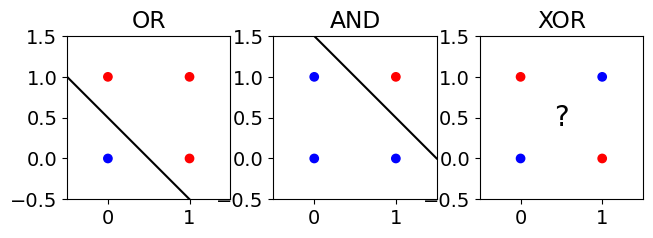

In [ ]:
import matplotlib.pyplot as plt

for i, Y in enumerate([Y_or, Y_and, Y_xor]):
    ax = plt.subplot(131 + i)
    ax.set_xlim([-0.5, 1.5])
    ax.set_ylim([-0.5, 1.5])
    ax.set_aspect('equal')

    plt.title(gates[i])
    plt.scatter(*zip(*X), c=Y, cmap='bwr')

    if i == 0:
        plt.plot([-0.5, 1], [1, -0.5], 'k')
    elif i == 1:
        plt.plot([0, 1.5], [1.5, 0], 'k')
    else:
        plt.text(0.5, 0.5, s="?", fontsize=20, ha='center', va='center')

plt.tight_layout()

- single perceptron is not able to capture XOR gate working

Now stack two perceptons and make the network deep

In [ ]:
class PerceptronDeep(torch.nn.Module):
    # constructor
    def __init__(self, hidden_size):
        super(PerceptronDeep, self).__init__()
        self.hidden_layer = nn.Linear(2, hidden_size)
        self.output_layer = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()
    # mathod called once the model is executed
    def forward(self, x):
        x = self.hidden_layer(x)
        x = self.sigmoid(x)
        x = self.output_layer(x)
        return self.sigmoid(x)

# train
N_epochs = 100000

for gate, y_gt in zip(gates, (Y_or, Y_and, Y_xor)):
    # define model and learnig scheme
    model = PerceptronDeep(hidden_size=2)
    optimizer = optim.SGD(model.parameters(), lr=0.5)
    # start training
    train_loss = []
    model.train()  # turn on the training mode
    for _ in range(N_epochs):
        # this will zero out the gradients for this batch
        optimizer.zero_grad()
        # make predictions
        y_pred = model(X)
        # calculate the MSE loss
        loss = MSE(y_pred, y_gt)
        # backpropagate the loss
        loss.backward()
        # update the model weights (with assumed learning rate)
        optimizer.step()
        train_loss.append(loss.item())
    print("last loss value = ", train_loss[-1])
    model.eval()
    for i, x in enumerate(X):
        print("{} {} {} -> {}".format(x[0].item(), gate, x[1].item(), model(x).item()))
    print()

last loss value =  1.9889625036739744e-05
0.0 OR 0.0 -> 0.0070689041167497635
0.0 OR 1.0 -> 0.9961608648300171
1.0 OR 0.0 -> 0.99623703956604
1.0 OR 1.0 -> 0.9991700649261475

last loss value =  1.5360861652879976e-05
0.0 AND 0.0 -> 0.00022210822498891503
0.0 AND 1.0 -> 0.003941709641367197
1.0 AND 0.0 -> 0.003929676953703165
1.0 AND 1.0 -> 0.994485080242157

last loss value =  5.1825129048665985e-05
0.0 XOR 0.0 -> 0.007195078767836094
0.0 XOR 1.0 -> 0.9932025074958801
1.0 XOR 0.0 -> 0.9917524456977844
1.0 XOR 1.0 -> 0.006426684092730284



- ... while the deep model is able to capture XOR gate.

#TASK 1: linie decyzyjne dla DeepPerceptrons

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# define basic logic gates
X = torch.tensor([[0,0], [0,1], [1,0], [1,1]], dtype=torch.float32)
gates = ("OR", "AND", "XOR")
# labels
Y_or = torch.tensor([0, 1, 1, 1], dtype=torch.float32).view(-1, 1)
Y_and = torch.tensor([0, 0, 0, 1], dtype=torch.float32).view(-1, 1)
Y_xor = torch.tensor([0, 1, 1, 0], dtype=torch.float32).view(-1, 1)

class PerceptronDeep(torch.nn.Module):
    # constructor
    def __init__(self, hidden_size):
        super(PerceptronDeep, self).__init__()
        self.hidden_layer = nn.Linear(2, hidden_size)
        self.output_layer = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()
    # mathod called once the model is executed
    def forward(self, x):
        x = self.hidden_layer(x)
        x = self.sigmoid(x)
        x = self.output_layer(x)
        return self.sigmoid(x)

MSE = nn.MSELoss()

# TRAIN
N_epochs = 100000

trained_models = {}
train_losses = {}

for gate, y_gt in zip(gates, (Y_or, Y_and, Y_xor)):

    # MODEL
    model = PerceptronDeep(hidden_size=2)
    optimizer = optim.SGD(model.parameters(), lr=0.5)

    train_loss = []
    model.train()

    for _ in range(N_epochs):
        optimizer.zero_grad()

        y_pred = model(X)
        loss = MSE(y_pred, y_gt)

        loss.backward()
        optimizer.step()

        train_loss.append(loss.item())

    print(gate, "last loss value =", train_loss[-1])

    # ZAPIS MODELU I HISTORII STRATY W PAMIĘCI
    trained_models[gate] = model
    train_losses[gate] = train_loss

OR last loss value = 2.2380583686754107e-05
AND last loss value = 2.0886092897853814e-05
XOR last loss value = 5.179128856980242e-05


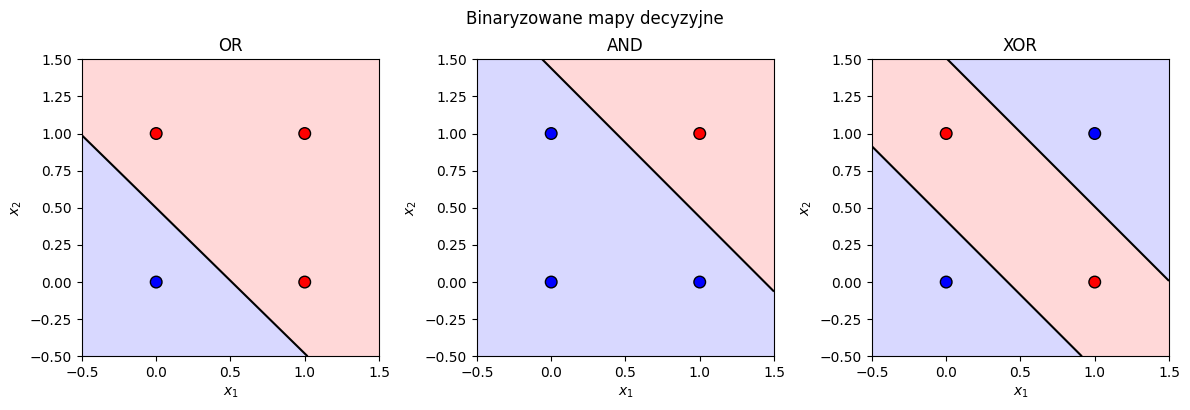

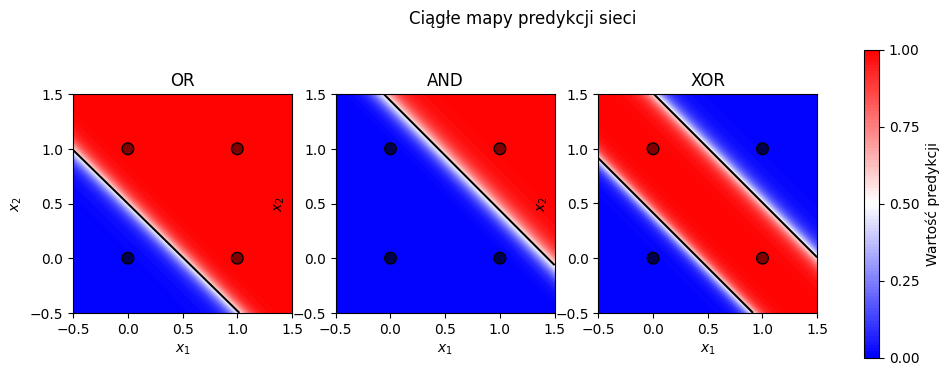

In [ ]:
import matplotlib.pyplot as plt
# SIATKA PUNKTÓW
x1 = np.linspace(-0.5, 1.5, 300)
x2 = np.linspace(-0.5, 1.5, 300)

xx, yy = np.meshgrid(x1, x2)
grid = np.column_stack([xx.ravel(), yy.ravel()])
grid_tensor = torch.tensor(grid, dtype=torch.float32)

# DANE I NAZWY BRAMEK
targets = {
    "OR": Y_or,
    "AND": Y_and,
    "XOR": Y_xor
}

# PREDYKCJE OBLICZAMY RAZ
predictions = {}

for gate, model in trained_models.items():
    model.eval()

    with torch.no_grad():
        pred = model(grid_tensor).cpu().numpy()

    predictions[gate] = pred.reshape(xx.shape)


# ==================================================
# WYKRES 1: BINARYZOWANA MAPA DECYZYJNA
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, gate in zip(axes, gates):
    pred = predictions[gate]
    y_gt = targets[gate].numpy().ravel()

    ax.set_xlim([-0.5, 1.5])
    ax.set_ylim([-0.5, 1.5])
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.set_title(gate)

    # Dwa obszary: predykcja poniżej i powyżej 0.5
    ax.contourf(
        xx, yy, pred,
        levels=[0, 0.5, 1],
        alpha=0.3,
        cmap="bwr"
    )

    # Granica decyzyjna
    ax.contour(
        xx, yy, pred,
        levels=[0.5],
        colors="black"
    )

    # Punkty treningowe
    ax.scatter(
        X[:, 0].numpy(),
        X[:, 1].numpy(),
        c=y_gt,
        cmap="bwr",
        vmin=0,
        vmax=1,
        edgecolors="black",
        s=70
    )

plt.suptitle("Binaryzowane mapy decyzyjne")
plt.tight_layout()
plt.show()


# ==================================================
# WYKRES 2: CIĄGŁA HEAT MAPA PREDYKCJI
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, gate in zip(axes, gates):
    pred = predictions[gate]
    y_gt = targets[gate].numpy().ravel()

    ax.set_xlim([-0.5, 1.5])
    ax.set_ylim([-0.5, 1.5])
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.set_title(gate)

    # Ciągła mapa: pokazuje wartości od 0 do 1
    heatmap = ax.contourf(
        xx, yy, pred,
        levels=100,
        cmap="bwr",
        vmin=0,
        vmax=1
    )

    # Granica decyzyjna
    ax.contour(
        xx, yy, pred,
        levels=[0.5],
        colors="black"
    )

    # Punkty treningowe
    ax.scatter(
        X[:, 0].numpy(),
        X[:, 1].numpy(),
        c=y_gt,
        cmap="seismic",
        vmin=0,
        vmax=1,
        edgecolors="black",
        s=70
    )

# Wspólna skala kolorów
fig.colorbar(
    heatmap,
    ax=axes,
    label="Wartość predykcji",
    ticks=[0, 0.25, 0.5, 0.75, 1]
)

plt.suptitle("Ciągłe mapy predykcji sieci")
#plt.tight_layout()
plt.show()

# TASK 1: DODAWANIE LICZB BINARNYCH

dodawanie liczby dwu-bitowych

ostatnie MSE =  0.0007742257439531386
0 + 0 -> [0.0011, 0.0386] -> [00]
0 + 1 -> [0.0187, 0.9625] -> [01]
1 + 0 -> [0.0125, 0.9648] -> [01]
1 + 1 -> [0.9785, 0.0329] -> [10]



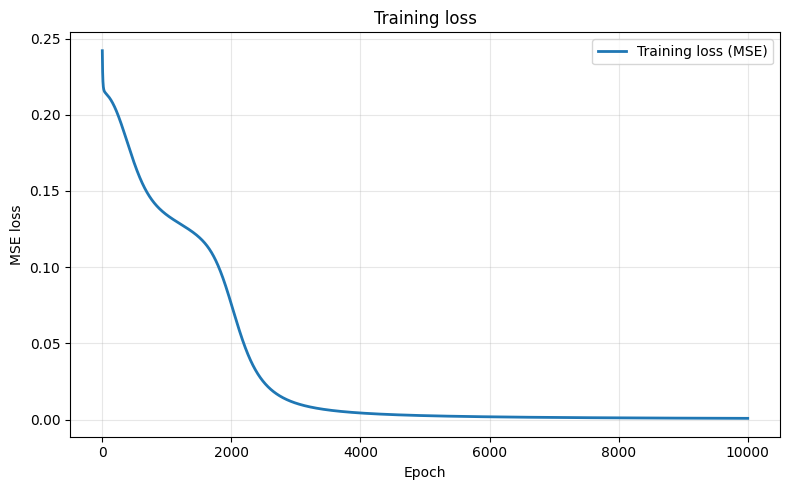

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# define binary addition
X = torch.tensor([[0,0], [0,1], [1,0], [1,1]], dtype=torch.float32)

# labels [carry, sum]
Y = torch.tensor([[0,0], [0,1], [0,1], [1,0]], dtype=torch.float32)

class Perceptron(torch.nn.Module): # dziedziczenie po klasie z pyTorch'a
    # constructor
    def __init__(self, size): # self - obiekt; size - określa liczbę wejść
        super(Perceptron, self).__init__() # To musi być zawsze napisane
        self.hidden_neurons = nn.Linear(size, 4) # Tworzy warstwę ukrytą liniową; pierwsza liczba wejśća druga wyjśćia
        self.output_neurons = nn.Linear(4, 2) # Definicja wyjścia
        self.sigmoid = nn.Sigmoid() # funkcja aktywacji

    # method called once the model is executed
    def forward(self, x): # Opisuje co dzieję się z danymi jak przechodzą przez sieć
        x = self.sigmoid(self.hidden_neurons(x)) # Przejśćje orzez warstwe ukrytną: hidden_neurons
        return self.sigmoid(self.output_neurons(x)) # Aplikowania funkcji aktwacji

# define model and learning scheme
model = Perceptron(size=2) # Tworzymy konkretną sieć wrzucamy size
optimizer = optim.SGD(model.parameters(), lr=0.5) # Wybór metody optymalizowania SGD - stochastyczny spadek gradientowy.
MSE = nn.MSELoss() # funckja błędu MSE - funkcję błędu średniokwadratowego

# train
N_epochs = 10000
train_loss = [] # miejsce gdzie zapiszą się wyniki funkcji błędu
model.train()  # turn on the training mode

for _ in range(N_epochs): # Podkreśelnie w pętli oznacza że nie zamierza się używac indeksu
    # this will zero out the gradients for this batch
    optimizer.zero_grad() # Zerowanie optimizera też zawszę będzie
    # make predictions
    y_pred = model(X) # wyniki z zasotowania sieci raz na dane
    # calculate the MSE loss
    loss = MSE(y_pred, Y) # liczenie błędu
    # backpropagate the loss
    loss.backward() # liczy gradeniet przy zadanych wagach
    # update the model weights (with assumed learning rate)
    optimizer.step() # za pomocą policzonego grandientu przesuwamy się w przestrzeni prametrów w_i
    train_loss.append(loss.item()) # zapisywanie historii błędu dla wszystkich epok

print("ostatnie MSE = ", train_loss[-1])

# test
model.eval()
for i, x in enumerate(X):
    with torch.no_grad():
        y_pred = model(x)
        y_binary = (y_pred > 0.5).int() # zbinaryzowanie

# wyświetlanie wyników działania sieci
    print("{} + {} -> [{:.4f}, {:.4f}] -> [{}{}]".format(
        int(x[0].item()),
        int(x[1].item()),
        y_pred[0].item(),
        y_pred[1].item(),
        y_binary[0].item(),
        y_binary[1].item(),

    ))
print()

# LOSS PLOT
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, N_epochs + 1), train_loss, linewidth=2, label="Training loss (MSE)")

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


Dodawanie pierwsza próba uogólnienia:

Ostatnie MSE = 0.0005612806417047977

TRAINING
00 + 00 = 000 (expected: 000)
01 + 01 = 010 (expected: 010)
00 + 10 = 010 (expected: 010)
10 + 00 = 010 (expected: 010)
01 + 11 = 100 (expected: 100)
11 + 01 = 100 (expected: 100)
10 + 11 = 101 (expected: 101)
11 + 10 = 101 (expected: 101)
00 + 01 = 001 (expected: 001)
01 + 00 = 001 (expected: 001)
00 + 11 = 011 (expected: 011)
11 + 00 = 011 (expected: 011)
10 + 01 = 011 (expected: 011)
10 + 10 = 100 (expected: 100)
01 + 10 = 011 (expected: 011)
Zgodność treningowa: 15/15

TEST!!!
11 + 11 = 100 (expected: 110)
Zgodność testowa: 0/1


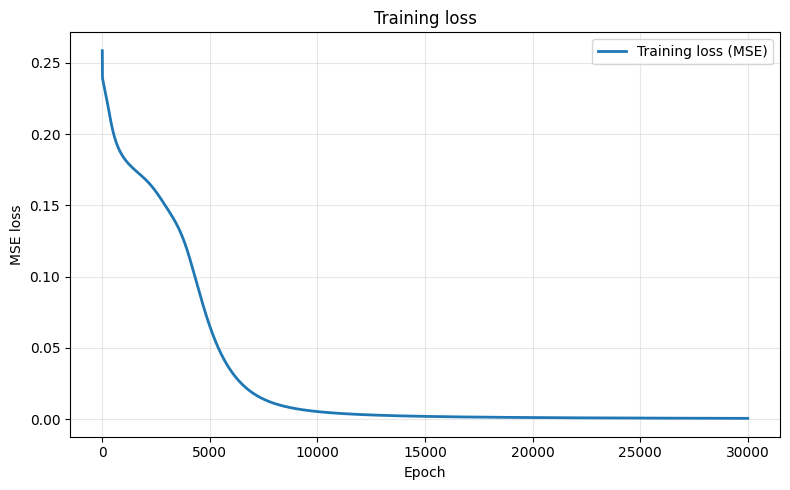

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# X, X_2 = [a1, a0, b1, b0]
X = torch.tensor([
    [0,0,0,0], # 00 + 00 = 000
    [0,1,0,1], # 01 + 01 = 010
    [0,0,1,0], # 00 + 10 = 010
    [1,0,0,0], # 10 + 00 = 010
    [0,1,1,1], # 01 + 11 = 100
    [1,1,0,1], # 11 + 01 = 100
    [1,0,1,1], # 10 + 11 = 101
    [1,1,1,0], # 11 + 10 = 101
    [0,0,0,1], # 00 + 01 = 001
    [0,1,0,0], # 01 + 00 = 001
    [0,0,1,1], # 00 + 11 = 011
    [1,1,0,0], # 11 + 00 = 011
    [1,0,0,1], # 10 + 01 = 011
    [1,0,1,0], # 10 + 10 = 100
    #[1,1,1,1], # 11 + 11 = 110
    [0,1,1,0]  # 01 + 10 = 011
], dtype=torch.float32)

# Y = [s2, s1, s0]
Y = torch.tensor([
    [0,0,0],
    [0,1,0],
    [0,1,0],
    [0,1,0],
    [1,0,0],
    [1,0,0],
    [1,0,1],
    [1,0,1],
    [0,0,1],
    [0,0,1],
    [0,1,1],
    [0,1,1],
    [0,1,1],
    [1,0,0],
    #[1,1,0],
    [0,1,1]
], dtype=torch.float32)

# Dane testowe
X_test = torch.tensor([
    #[0,0,0,0], # 00 + 00 = 000
    #[0,1,0,1], # 01 + 01 = 010
    #[0,0,1,0], # 00 + 10 = 010
    #[1,0,0,0], # 10 + 00 = 010
    #[0,1,1,1], # 01 + 11 = 100
    #[1,1,0,1], # 11 + 01 = 100
    #[1,0,1,1], # 10 + 11 = 101
    #[1,1,1,0], # 11 + 10 = 101
    #[0,0,0,1], # 00 + 01 = 001
    #[0,1,0,0], # 01 + 00 = 001
    #[0,0,1,1], # 00 + 11 = 011
    #[1,1,0,0], # 11 + 00 = 011
    #[1,0,0,1], # 10 + 01 = 011
    #[1,0,1,0], # 10 + 10 = 100
    [1,1,1,1],  # 11 + 11 = 110
    #[0,1,1,0]   # 01 + 10 = 011
], dtype=torch.float32)

Y_test = torch.tensor([
    #[0,0,0],
    #[0,1,0],
    #[0,1,0],
    #[0,1,0],
    #[1,0,0],
    #[1,0,0],
    #[1,0,1],
    #[1,0,1],
    #[0,0,1],
    #[0,0,1],
    #[0,1,1],
    #[0,1,1],
    #[0,1,1],
    #[1,0,0],
    [1,1,0],
    #[0,1,1]
], dtype=torch.float32)

# define model
class Perceptron(torch.nn.Module):
    def __init__(self, size):
        super(Perceptron, self).__init__()
        self.hidden_neurons = nn.Linear(size, 32)
        self.output_neurons = nn.Linear(32, 3)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        x = self.sigmoid(self.hidden_neurons(x))
        return self.sigmoid(self.output_neurons(x))

# define model and learning scheme
model = Perceptron(size=4)
optimizer = optim.SGD(model.parameters(), lr=0.5)
MSE = nn.MSELoss()

# train
N_epochs = 30000
train_loss = []
model.train()
for _ in range(N_epochs):
    optimizer.zero_grad()
    y_pred = model(X)
    loss = MSE(y_pred, Y)
    loss.backward()
    optimizer.step()
    train_loss.append(loss.item())

print("Ostatnie MSE =", train_loss[-1])
print()

# test - dodawania niewidziane podczas treningu
model.eval()
with torch.no_grad():
    # Wyniki treningowe
    correct_train = 0
    print("TRAINING")
    for i, x in enumerate(X):
        y_pred = model(x)
        y_binary = (y_pred > 0.5).int()
        a = f"{int(x[0])}{int(x[1])}"
        b = f"{int(x[2])}{int(x[3])}"
        #wynik = f"{(y_pred[0])}{(y_pred[1])}{(y_pred[2])}"
        wynik = f"{int(y_binary[0])}{int(y_binary[1])}{int(y_binary[2])}"
        expected = f"{int(Y[i][0])}{int(Y[i][1])}{int(Y[i][2])}"

        if wynik == expected:
            correct_train += 1
        print(f"{a} + {b} = {wynik} (expected: {expected})")

    print(f"Zgodność treningowa: {correct_train}/{len(X)}")
    print()

    # Wyniki testowe
    correct = 0
    print("TEST!!!")
    for i, x in enumerate(X_test):
        y_pred = model(x)
        y_binary = (y_pred > 0.5).int()
        a = f"{int(x[0])}{int(x[1])}"
        b = f"{int(x[2])}{int(x[3])}"
        #wynik = f"{(y_pred[0])}{(y_pred[1])}{(y_pred[2])}"
        wynik = f"{int(y_binary[0])}{int(y_binary[1])}{int(y_binary[2])}"
        expected = f"{int(Y_test[i][0])}{int(Y_test[i][1])}{int(Y_test[i][2])}"

        if wynik == expected:
            correct += 1
        print(f"{a} + {b} = {wynik} (expected: {expected})")

    print(f"Zgodność testowa: {correct}/{len(X_test)}")

# LOSS PLOT
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, N_epochs + 1), train_loss, linewidth=2, label="Training loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Dodawanie liczby n-bitowe do m-bitowej (z wykorzystaniem sporowadzenia zagadnienia do dodawania 2-bitowego z przeniesieniem):

Last loss value = 0.0004280232824385166

 a + b + w_pamieci_in -> [w_pamieci_out, sum]

bit1:0 + bit2:0 + w pamieci:0 -> Wyniki modelu:[0.0000, 0.0140] -> bit:0; w pamieci:0
bit1:0 + bit2:0 + w pamieci:1 -> Wyniki modelu:[0.0187, 0.9798] -> bit:0; w pamieci:1
bit1:0 + bit2:1 + w pamieci:0 -> Wyniki modelu:[0.0167, 0.9815] -> bit:0; w pamieci:1
bit1:0 + bit2:1 + w pamieci:1 -> Wyniki modelu:[0.9865, 0.0248] -> bit:1; w pamieci:0
bit1:1 + bit2:0 + w pamieci:0 -> Wyniki modelu:[0.0158, 0.9828] -> bit:0; w pamieci:1
bit1:1 + bit2:0 + w pamieci:1 -> Wyniki modelu:[0.9859, 0.0293] -> bit:1; w pamieci:0
bit1:1 + bit2:1 + w pamieci:0 -> Wyniki modelu:[0.9752, 0.0285] -> bit:1; w pamieci:0
bit1:1 + bit2:1 + w pamieci:1 -> Wyniki modelu:[0.9996, 0.9620] -> bit:1; w pamieci:1



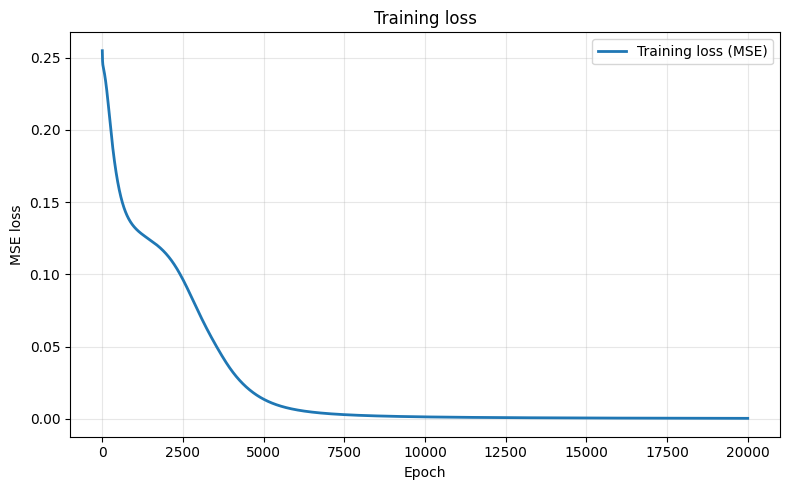

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# inputs [a, b, w_pamieci_in]
X = torch.tensor([
    [0,0,0],
    [0,0,1],
    [0,1,0],
    [0,1,1],
    [1,0,0],
    [1,0,1],
    [1,1,0],
    [1,1,1]
], dtype=torch.float32)

# labels [w_pamieci_out, sum]
Y = torch.tensor([
    [0,0],
    [0,1],
    [0,1],
    [1,0],
    [0,1],
    [1,0],
    [1,0],
    [1,1]
], dtype=torch.float32)

# let's define a model
class Perceptron(torch.nn.Module):
    # constructor
    def __init__(self, size):
        super(Perceptron, self).__init__()
        self.hidden_neurons = nn.Linear(size, 8)
        self.output_neurons = nn.Linear(8, 2)
        self.sigmoid = nn.Sigmoid()
    # method called once the model is executed
    def forward(self, x):
        x = self.sigmoid(self.hidden_neurons(x))
        return self.sigmoid(self.output_neurons(x))
# define model and learning scheme
model = Perceptron(size=3)
optimizer = optim.SGD(model.parameters(), lr=0.5)
MSE = nn.MSELoss()

# train
N_epochs = 20000
train_loss = []
model.train()
for _ in range(N_epochs):
    optimizer.zero_grad()
    y_pred = model(X)
    loss = MSE(y_pred, Y)
    loss.backward()
    optimizer.step()
    train_loss.append(loss.item())
print("Last loss value =", train_loss[-1])

# test
model.eval()
print("\n a + b + w_pamieci_in -> [w_pamieci_out, sum]\n")
for x in X:
    with torch.no_grad():
        y_pred = model(x)
        y_binary = (y_pred > 0.5).int()
    print("bit1:{} + bit2:{} + w pamieci:{} -> Wyniki modelu:[{:.4f}, {:.4f}] -> bit:{}; w pamieci:{}".format(
        int(x[0].item()),
        int(x[1].item()),
        int(x[2].item()),
        y_pred[0].item(),
        y_pred[1].item(),
        y_binary[0].item(),
        y_binary[1].item()
    ))
print()

# LOSS PLOT
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, N_epochs + 1), train_loss, linewidth=2, label="Training loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


użycie wyżej storzonej sieci:

In [ ]:
#Wykorzystywanie tego dodawania bitowego
def add_binary(a, b, model):
    n = max(len(a), len(b))
    a = a.zfill(n) # wyrównywanie długośći obu liczb bitowych dopisywanie zer z przodu
    b = b.zfill(n) # funkcja zfill właśnie to robi dopisuje zera z lewj strony aż zapis bitowy miał dokaładnie n długość
    w_pamieci = 0
    wynik = ""
    model.eval()
    with torch.no_grad(): # wyłacza obliczanie gradientów, używamy teraz sieci i jej wag
        # add bits from right to left
        for i in range(n - 1, -1, -1): # range(start, stop, step), chcemy dodawać od prawej do lewej
            x = torch.tensor([int(a[i]), int(b[i]), w_pamieci], dtype=torch.float32)
            # po zadziałniu modelem wyniki [w_pamieci_out, sum]
            y_pred = model(x)
            y_binary = (y_pred > 0.5).int() # binaryzowanie
            w_pamieci = int(y_binary[0].item())
            sum_bit = int(y_binary[1].item())
            wynik = str(sum_bit) + wynik
    # ostatnie przenieśienie jesli zostanie coś w pamięci
    if w_pamieci == 1:
        wynik = "1" + wynik
    return wynik

# test binary addition
a = "1011"
b = "110"
wynik_dodawania = add_binary(a, b, model)
print()
print(f"{a} + {b} = {wynik_dodawania}")


1011 + 110 = 10001


# TASK 2: Porówanie dwóch typów sieci nueronowych (Shalllow NN vs DEEP NN,  czyli Głębokość-Szerokość)
Wizualuzacja dwóch typów sieci:
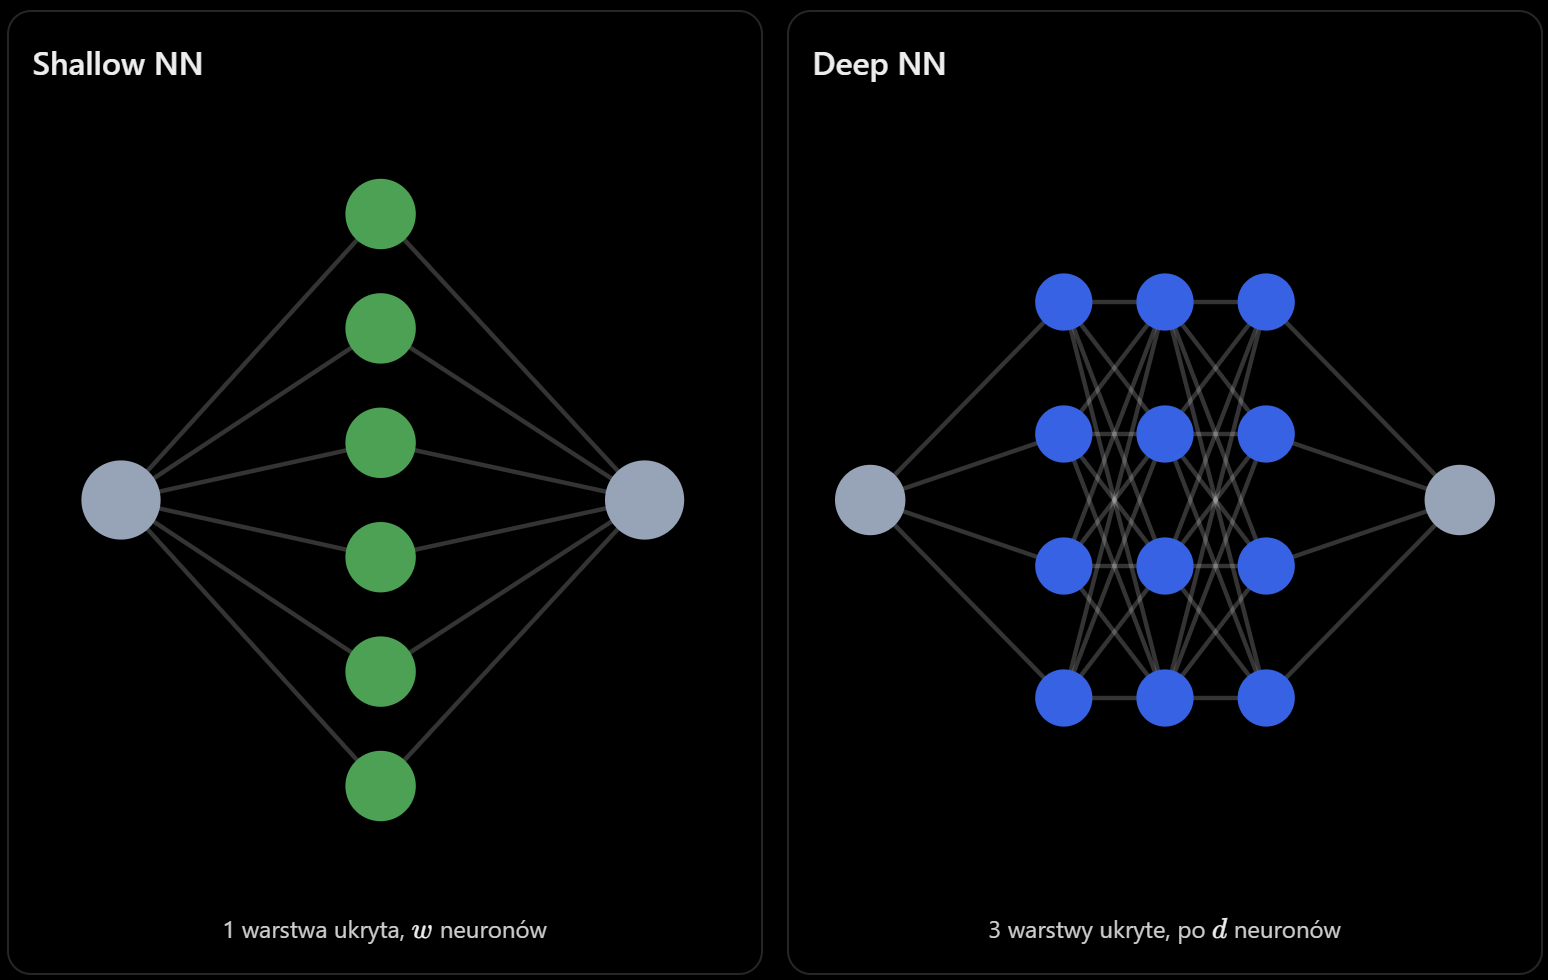

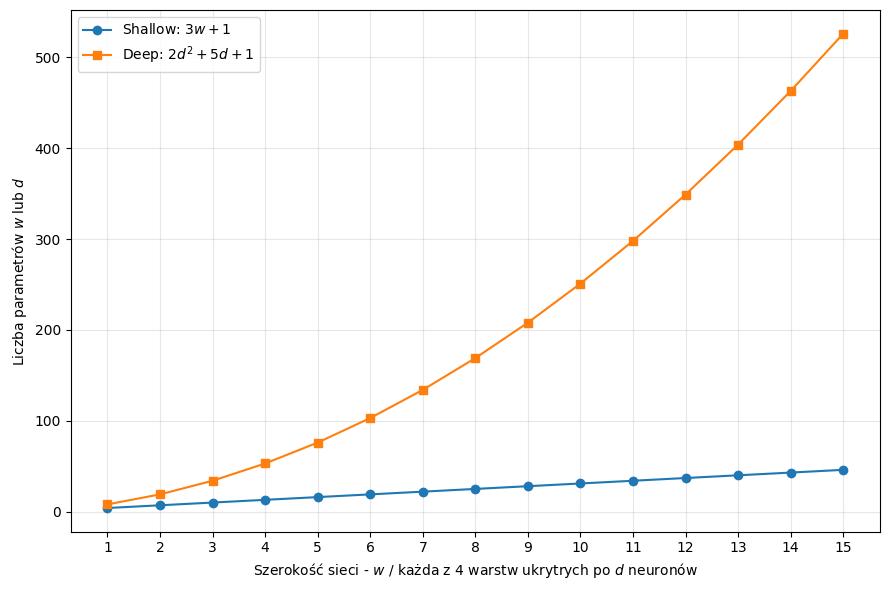

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

w_d = np.arange(1, 16, 1) #dziedzina, liczby naturalne
#liczba parametrów - korzystająć ze wzoru analitycznego - notatki
P_shallow = 3 * w_d + 1
P_deep = 2 * w_d**2 + 5 * w_d + 1

#wykres poglądowy
plt.figure(figsize=(9, 6))
plt.plot(w_d, P_shallow, 'o-', label=r'Shallow: $3w+1$')
plt.plot(w_d, P_deep, 's-', label=r'Deep: $2d^2+5d+1$')
plt.xlabel('Szerokość sieci - $w$ / każda z 4 warstw ukrytrych po $d$ neuronów')
plt.ylabel('Liczba parametrów $w$ lub $d$')
plt.xticks(np.arange(1, 16, 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Wybrana liczba prametrów:

SHALLOW NN                     DEEP NN                       
w               Parameters      d               Parameters     
------------------------------------------------------------
4               13              2               19             
8               25              2               19             
16              49              4               53             
32              97              6               103            
64              193             9               208            
128             385             13              404            




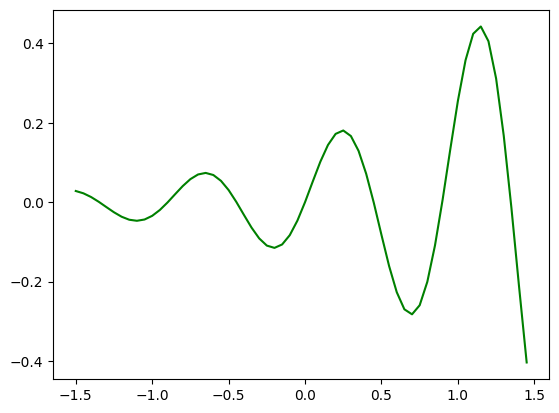

In [ ]:
#dobrane parmetry
shallow_w = [4, 8, 16, 32, 64, 128]
deep_d = [2, 2, 4, 6, 9, 13]

def P_shallow(w):
    return 3 * w + 1
def P_deep(d):
    return 2 * d**2 + 5 * d + 1

#wyswietlanie tabelki z porówanie liczebność prametrów
print(f"{'SHALLOW NN':<30} {'DEEP NN':<30}")
print(f"{'w':<15} {'Parameters':<15} {'d':<15} {'Parameters':<15}")
print("-" * 60)
for w, d in zip(shallow_w, deep_d):
    print(f"{w:<15} {P_shallow(w):<15} {d:<15} {P_deep(d):<15}")
print("\n")

#analizowana funkcja
X = torch.arange(-1.5, 1.5, 0.05).view(-1, 1).type(torch.float32)
y = torch.sin(X*7.)*torch.exp(X)/7.
plt.plot(X, y, 'g')
plt.show()

Definicje obu sieci:

In [ ]:
import torch
import torch.nn as nn

# SHALLOW NN - 1 warstwa ukryta
class ShallowNN(torch.nn.Module):
    def __init__(self, width):
        super(ShallowNN, self).__init__()
        self.hidden_neurons = nn.Linear(1, width)  #1 wejście, width neuronów
        self.output_neurons = nn.Linear(width, 1)  #width wejść, 1 wyjście
        self.sigmoid = nn.Sigmoid()  #funkcja aktywacji

    def forward(self, x):
        x = self.sigmoid(self.hidden_neurons(x))
        return self.output_neurons(x)


# DEEP NN - 3 warstwy ukryte
class DeepNN(torch.nn.Module):
    def __init__(self, width):
        super(DeepNN, self).__init__()
        self.hidden_neurons_1 = nn.Linear(1, width)      #pierwsza warstwa ukryta
        self.hidden_neurons_2 = nn.Linear(width, width)  #druga warstwa ukryta
        self.hidden_neurons_3 = nn.Linear(width, width)  #trzecia warstwa ukryta
        self.output_neurons = nn.Linear(width, 1)        #warstwa wyjściowa
        self.sigmoid = nn.Sigmoid()  #funkcja aktywacji

    def forward(self, x):
        x = self.sigmoid(self.hidden_neurons_1(x))
        x = self.sigmoid(self.hidden_neurons_2(x))
        x = self.sigmoid(self.hidden_neurons_3(x))
        return self.output_neurons(x)

Funkcja ternująca te 12 typów sieci:

In [ ]:
import torch
import torch.nn as nn
import copy

#dane testowe - przypominam je tutaj żeby nie trzeba było wywyoływać pierwszej komórki tego zadania ciagle
X_test = torch.linspace(-1.5, 1.5, 500).view(-1, 1)
y_test = torch.sin(X_test * 7.) * torch.exp(X_test) / 7.

def train_model(model, N_epochs=50000):
    MSE = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    #wyniki kżdego treningu
    mse_results = [] #MSE po konkretenj liczbie epok
    saved_models = [] #zapis całego modelu (wag itp.)
    epochs_history = [] #co 100 epok
    mse_history = [] #MSE co 100 epoko

    for epoch in range(N_epochs):
        #forward pass
        y_pred = model(X)
        loss = MSE(y_pred, y)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #pomiar MSE co 100 epok
        if (epoch+1) % 100 == 0:
            model.eval()
            with torch.no_grad(): #wyłącza liczenia gradinetów
                y_pred_test = model(X_test)
                mse = MSE(y_pred_test, y_test).item()

            epochs_history.append(epoch+1) #co 100 epok
            mse_history.append(mse) #MSE co 100 epoko

            #dodatkowy zapis po 5000 i 50000 epok całego wytrenowanego modelu
            if (epoch + 1) in [5000, 50000]:

                mse_results.append(mse) #MSE po konkretenj liczbie epok
                saved_models.append(copy.deepcopy(model)) #zapis całego modelu (wag itp.)

            model.train() #po zapisach waracmy do treningu

    return mse_results, epochs_history, mse_history, saved_models
    #foramt return
    #mse_results = [0.002, 0.0001]
    #epochs_history = [100, 200, 300, ..., 50000]
    #mse_history = [0.15, 0.12, 0.10, ..., 0.0001]
    #saved_models = [model_5000, model_50000]

Trening właściwy (około 10 min):

In [ ]:
torch.manual_seed(67) #jedno źródło losowości aby dla wszystkich sieci bdać tylko wpływ struktury a nie artefakty wynikające z inicjalizowanych/losowych wag
#to jest, tutaj powtarzam żeby nie trzeba było uruchamiać poprzednich
#shallow_w = [4, 8, 16, 32, 64, 128]
#deep_d = [2, 2, 4, 6, 9, 13]

results = [] #końcowe wyniki dla MSE
histories = [] #MSE zapisane co ileś tam epok
trained_models = {} #tutaj zapisuje się cały wytrenowany model (wagi itp.)

# SHALLOW NN
for run_id, w in enumerate(shallow_w, start=1):
    model = ShallowNN(w)
    mse_results, epochs_history, mse_history, saved_models = train_model(model)
    # Zapis wyników MSE
    for i, epoch in enumerate([5000, 50000]):
        results.append(["Shallow", w, P_shallow(w), epoch, mse_results[i], run_id])
        trained_models[("Shallow", run_id, epoch)] = saved_models[i]
    histories.append(["Shallow", w, P_shallow(w), epochs_history, mse_history, run_id])

    print(f"Shallow w={w} - completed")

# DEEP NN
for run_id, d in enumerate(deep_d, start=1):
    model = DeepNN(width=d)
    mse_results, epochs_history, mse_history, saved_models = train_model(model)

    # Zapis wyników MSE
    for i, epoch in enumerate([5000, 50000]):
        results.append(["Deep", d, P_deep(d), epoch, mse_results[i], run_id])
        trained_models[("Deep", run_id, epoch)] = saved_models[i]
    histories.append(["Deep", d, P_deep(d), epochs_history, mse_history, run_id])

    print(f"Deep d={d} - completed")

Shallow w=4 - completed
Shallow w=8 - completed
Shallow w=16 - completed
Shallow w=32 - completed
Shallow w=64 - completed
Shallow w=128 - completed
Deep d=2 - completed
Deep d=2 - completed
Deep d=4 - completed
Deep d=6 - completed
Deep d=9 - completed
Deep d=13 - completed


Wykres funkcji Loss dla wszystkich modeli:


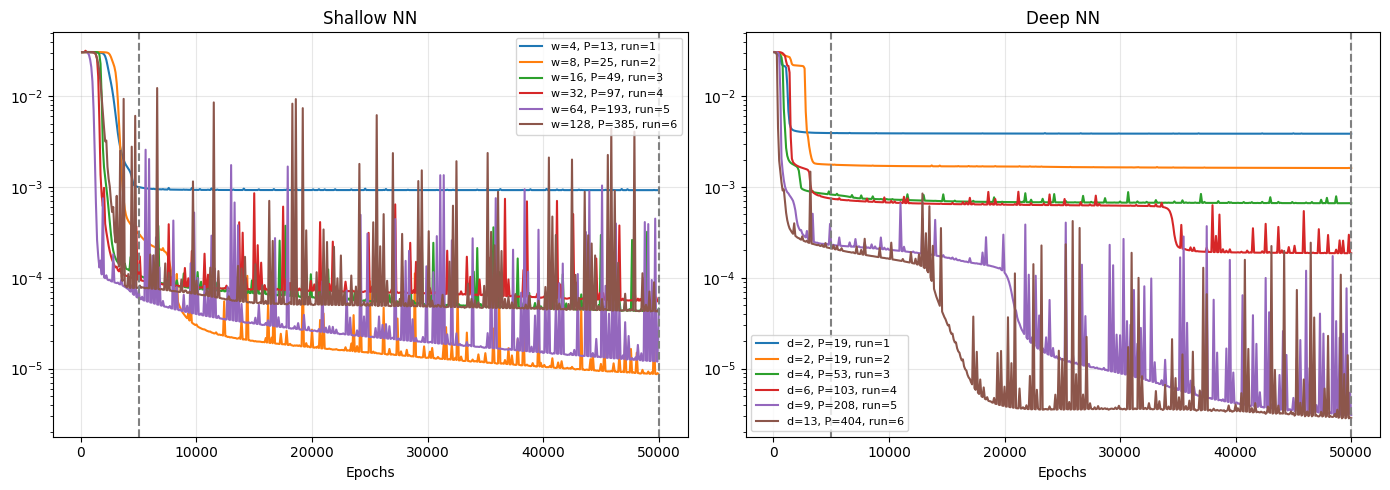

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for model_name, width, parameters, epochs_history, mse_history, run_id in histories:
    if model_name == "Shallow":
        ax = axes[0]
    else:
        ax = axes[1]
    ax.plot(epochs_history, mse_history, label=f'{"w" if model_name == "Shallow" else "d"}={width}, P={parameters}, run={run_id}')

titles = ["Shallow NN", "Deep NN"]
for i in range(2):
    ax = axes[i]
    title = titles[i]
    ax.axvline(5000, color='gray', linestyle='--')
    ax.axvline(50000, color='gray', linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Epochs')
    ax.set_yscale('log')
    ax.tick_params(axis='y', labelleft=True)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Porówanie:

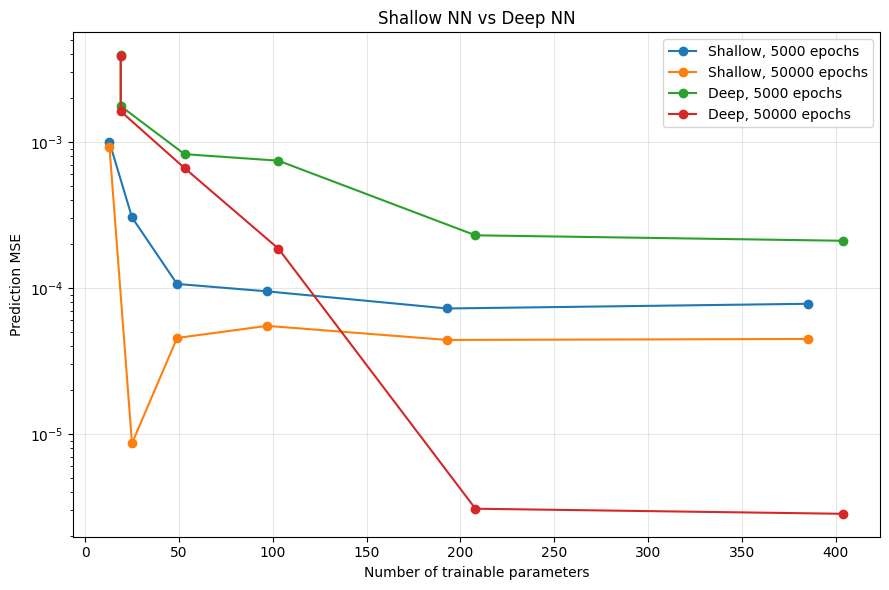

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
for model_name in ["Shallow", "Deep"]:
    for epoch in [5000, 50000]:
        data = [r for r in results if r[0] == model_name and r[3] == epoch]
        data.sort(key=lambda r: r[2])
        parameters = [r[2] for r in data]
        mse = [r[4] for r in data]
        plt.plot(parameters, mse, 'o-', label=f'{model_name}, {epoch} epochs')

plt.xlabel('Number of trainable parameters')
plt.ylabel('Prediction MSE')
plt.title('Shallow NN vs Deep NN')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Możliwość pokazania resultatów dal każdego z 12 modeli:

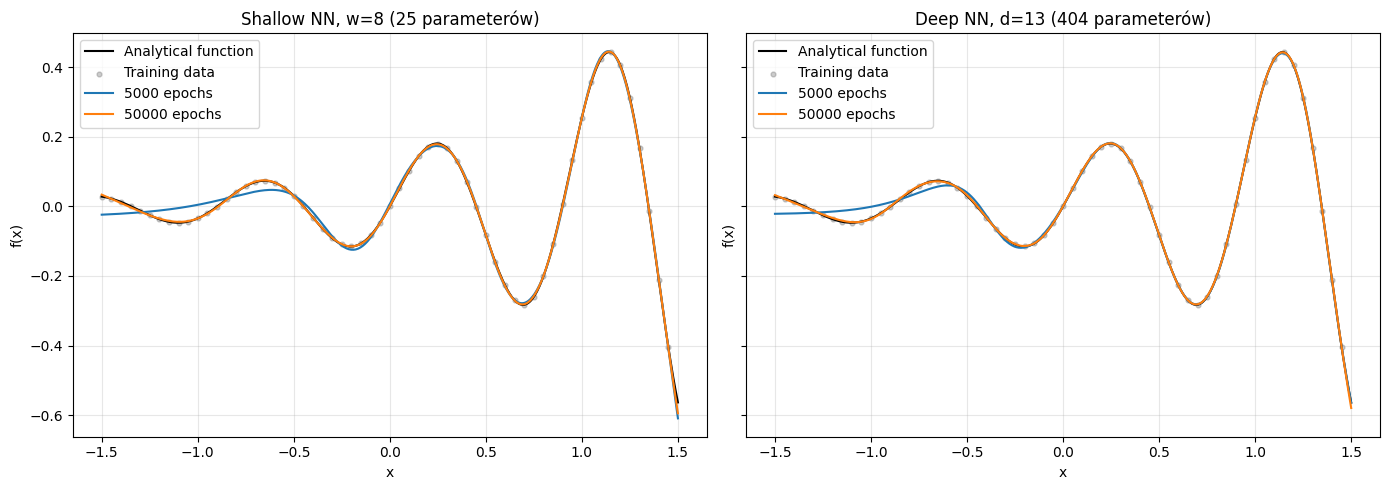

In [ ]:
# Wybór sieci (numer na liście, od 1)
#shallow_w = [4, 8, 16, 32, 64, 128]
#deep_d = [2, 2, 4, 6, 9, 13]
shallow_id = 2
deep_id = 6

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

model_names = ["Shallow", "Deep"]
model_ids = [shallow_id, deep_id]
for i in range(2):
    ax = axes[i]
    model_name = model_names[i]
    run_id = model_ids[i]
    #funkcja analityczna
    ax.plot(X_test.numpy(), y_test.numpy(), 'k-', label="Analytical function")
    #punkty treningowe
    ax.scatter(X.numpy(), y.numpy(), color='gray', s=12, alpha=0.4, label="Training data")
    #predykcje zapisanych modeli
    for epoch in [5000, 50000]:
        model = trained_models[(model_name, run_id, epoch)]
        model.eval() #ewaluacja wybranego modelu dla 5000 i 50000 epok
        with torch.no_grad():
            y_pred = model(X_test).numpy()
        ax.plot(X_test.numpy(), y_pred, label=f'{epoch} epochs')

    if model_name == "Shallow":
      w = shallow_w[run_id - 1]
      ax.set_title(f'Shallow NN, w={w} ({P_shallow(w)} parameterów)')
    else:
      d = deep_d[run_id - 1]
      ax.set_title(f'Deep NN, d={d} ({P_deep(d)} parameterów)')

    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.grid(True, alpha = 0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# TASK 3: Missing data

In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd

X = torch.linspace(-1.5, 1.5, 500).view(-1, 1)

torch.manual_seed(42)

# Jedna liczba epok dla wszystkich modeli
N_EPOCHS = 50000

# Architektury
shallow_widths = [4, 8, 16, 32, 64, 128]
deep_widths = [2, 4, 6, 9, 13]

results = []
histories = []
trained_models = []

# Pełny zbiór danych
X_full = X.clone()
y_full = torch.sin(X_full * 7.) * torch.exp(X_full) / 7.

# Usuwamy punkty treningowe z przedziału [-0.5, 0.5]
x_values = X_full.reshape(-1)
mask = (x_values < -0.5) | (x_values > 0.5)

X_train = X_full[mask]
y_train = y_full[mask]

# Dane używane przez train_model()
X = X_train
y = y_train

# Gęsta siatka do rysowania predykcji na całym zakresie
x_min = X_full.min().item()
x_max = X_full.max().item()

X_plot = torch.linspace(
    x_min, x_max, 1000
).reshape(-1, 1)

y_plot_true = torch.sin(X_plot * 7.) * torch.exp(X_plot) / 7.

# Siatka wewnątrz luki do obliczenia MSE
gap_mask = (X_plot.reshape(-1) >= -0.5) & (
    X_plot.reshape(-1) <= 0.5
)
X_gap = X_plot[gap_mask]
y_gap_true = y_plot_true[gap_mask]

# SHALLOW NN
for w in shallow_widths:
    model = ShallowNN(width=w)

    mse_results, epochs_history, mse_history, saved_models = train_model(model)

    parameters = sum(p.numel() for p in model.parameters())

    results.append([
    "Shallow", w, parameters,
    len(mse_results), mse_results[-1]
    ])

    histories.append([
        "Shallow", w, parameters,
        epochs_history, mse_history
    ])

    model.eval()
    with torch.no_grad():
        y_pred_gap = model(X_gap)
        mse_gap = torch.mean(
            (y_pred_gap - y_gap_true) ** 2
        ).item()

    trained_models.append({
        "type": "Shallow",
        "width": w,
        "parameters": parameters,
        "model": model,
        "mse_gap": mse_gap
    })

    print(
        f"Shallow width={w}, parameters={parameters}, "
        f"MSE gap={mse_gap:.6e} - completed"
    )

# DEEP NN
for d in deep_widths:
    model = DeepNN(width=d)

    mse_results, epochs_history, mse_history, saved_models = train_model(model)

    parameters = sum(p.numel() for p in model.parameters())

    results.append([
        "Deep", d, parameters,
        len(mse_results), mse_results[-1]
    ])

    histories.append([
        "Deep", d, parameters,
        epochs_history, mse_history
    ])

    model.eval()
    with torch.no_grad():
        y_pred_gap = model(X_gap)
        mse_gap = torch.mean(
            (y_pred_gap - y_gap_true) ** 2
        ).item()

    trained_models.append({
        "type": "Deep",
        "width": d,
        "parameters": parameters,
        "model": model,
        "mse_gap": mse_gap
    })

    print(
        f"Deep width={d}, parameters={parameters}, "
        f"MSE gap={mse_gap:.6e} - completed"
    )

print("\nAll training completed!")

# Tabela wyników
gap_results = pd.DataFrame([
    {
        "Architecture": item["type"],
        "Width": item["width"],
        "Parameters": item["parameters"],
        "MSE in gap": item["mse_gap"]
    }
    for item in trained_models
])

print("\nMSE inside the missing region:")
print(gap_results.to_string(index=False))

# Konwersja do NumPy na potrzeby wykresów
x_plot_np = X_plot.detach().cpu().reshape(-1).numpy()
y_true_np = y_plot_true.detach().cpu().reshape(-1).numpy()

x_train_np = X_train.detach().cpu().reshape(-1).numpy()
y_train_np = y_train.detach().cpu().reshape(-1).numpy()

Shallow width=4, parameters=13, MSE gap=1.209339e-02 - completed
Shallow width=8, parameters=25, MSE gap=5.511921e-04 - completed
Shallow width=16, parameters=49, MSE gap=5.095735e-02 - completed
Shallow width=32, parameters=97, MSE gap=1.798330e-01 - completed
Shallow width=64, parameters=193, MSE gap=6.257163e-03 - completed
Shallow width=128, parameters=385, MSE gap=1.023689e-02 - completed
Deep width=2, parameters=19, MSE gap=1.135066e-02 - completed
Deep width=4, parameters=53, MSE gap=9.247391e-03 - completed
Deep width=6, parameters=103, MSE gap=1.407503e-02 - completed
Deep width=9, parameters=208, MSE gap=6.997933e-03 - completed
Deep width=13, parameters=404, MSE gap=1.095858e-02 - completed

All training completed!

MSE inside the missing region:
Architecture  Width  Parameters  MSE in gap
     Shallow      4          13    0.012093
     Shallow      8          25    0.000551
     Shallow     16          49    0.050957
     Shallow     32          97    0.179833
     Shallow

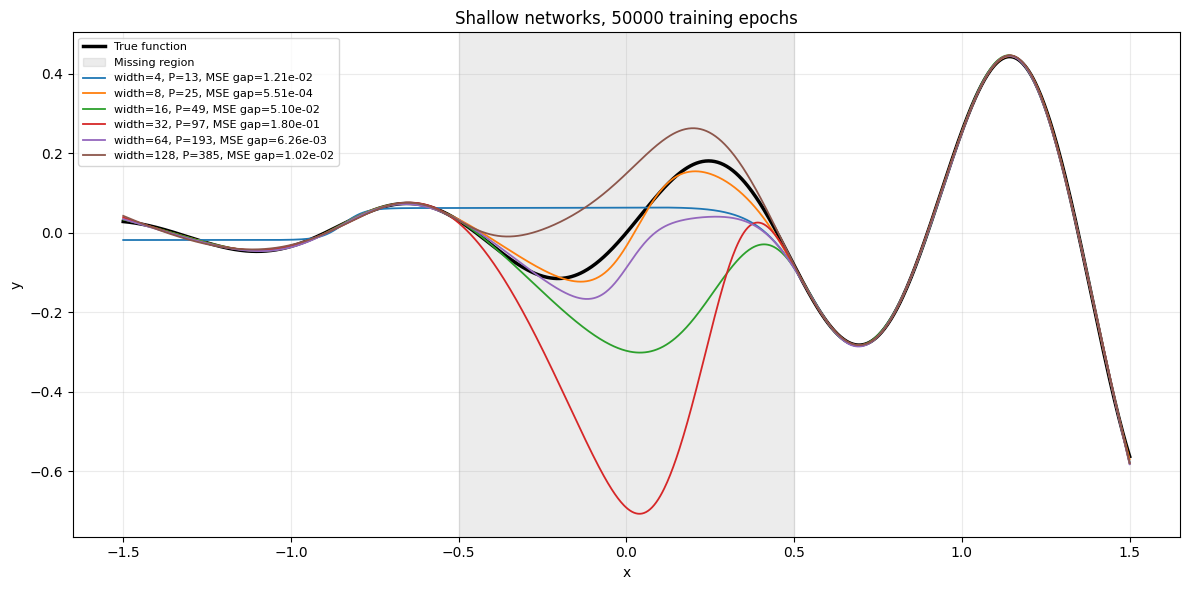

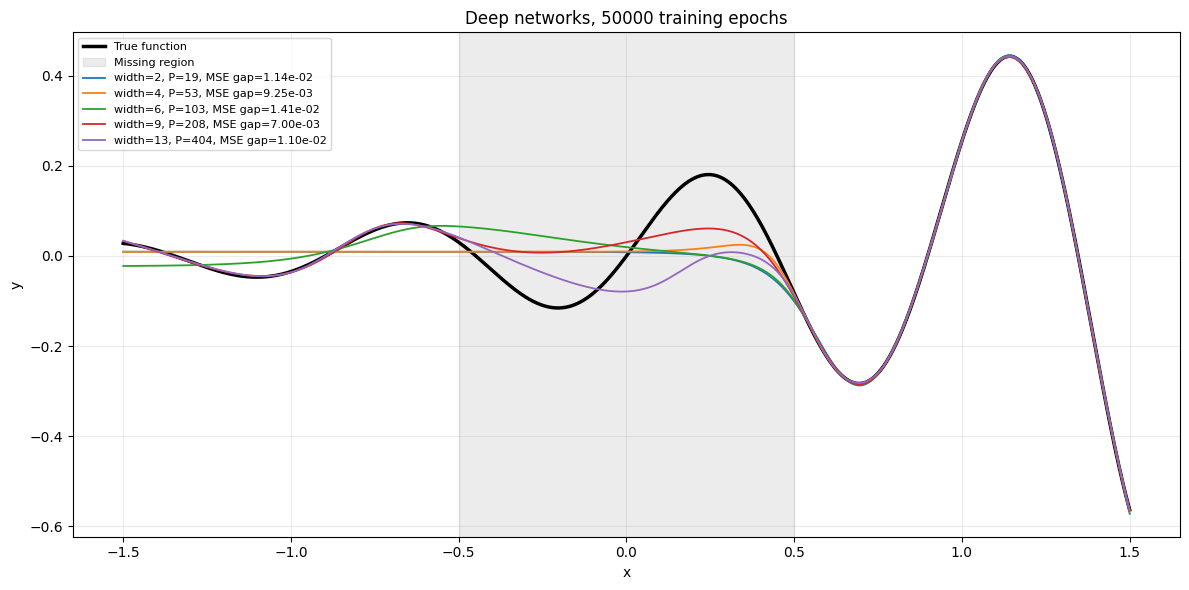

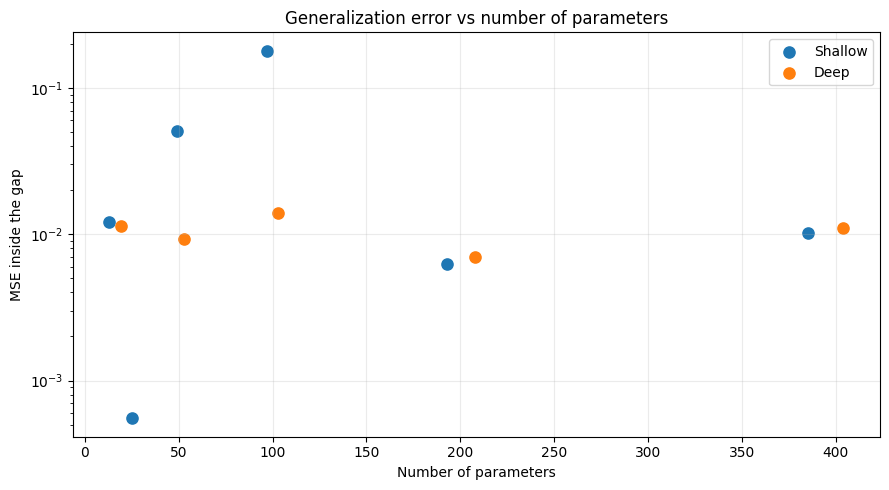

In [ ]:
# Predykcje obu architektur na CAŁYM zakresie
for architecture in ["Shallow", "Deep"]:
    models = [
        item for item in trained_models
        if item["type"] == architecture
    ]

    fig, ax = plt.subplots(figsize=(12, 6))

    # Prawdziwa funkcja
    ax.plot(
        x_plot_np, y_true_np,
        color="black", linewidth=2.5,
        label="True function"
    )

    # Punkty treningowe
    # ax.scatter(
    #     x_train_np, y_train_np,
    #     color="gray", s=14, alpha=0.55,
    #     label="Training data", zorder=3
    # )

    # Zaznaczenie luki
    ax.axvspan(
        -0.5, 0.5,
        color="gray", alpha=0.15,
        label="Missing region"
    )

    # Predykcje modeli na całym zakresie
    for item in models:
        item["model"].eval()

        with torch.no_grad():
            prediction = (
                item["model"](X_plot)
                .detach().cpu().reshape(-1).numpy()
            )

        ax.plot(
            x_plot_np, prediction,
            linewidth=1.3,
            label=(
                f'width={item["width"]}, '
                f'P={item["parameters"]}, '
                f'MSE gap={item["mse_gap"]:.2e}'
            )
        )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(
        f"{architecture} networks, {N_EPOCHS} training epochs"
    )
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# Porównanie MSE w luce
fig, ax = plt.subplots(figsize=(9, 5))

for architecture in ["Shallow", "Deep"]:
    subset = gap_results[
        gap_results["Architecture"] == architecture
    ]

    ax.scatter(
        subset["Parameters"],
        subset["MSE in gap"],
        s=65, label=architecture
    )

ax.set_xlabel("Number of parameters")
ax.set_ylabel("MSE inside the gap")
ax.set_title("Generalization error vs number of parameters")
ax.set_yscale("log")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Przywrócenie pełnych danych
X = X_full
y = y_full